# Titanic — look first, hypothesise second, confirm out-of-fold

> **Result: 0.840 accuracy under 20× repeated 5-fold CV, 0.799 public LB** (§12 explains the gap), from a three-line family
> rule that beats gradient boosting. No leaked labels. Every comparison carries its paired standard error, and the notebook runs on CPU in ~1.5 min.

**Competition:** [Titanic](https://www.kaggle.com/competitions/titanic) · **Metric:** accuracy · **Data:** 891 labelled passengers, 418 to predict.

### How this notebook works
It follows the order a careful analyst works in, and each stage uses only what earlier stages produced:

```
 §2  OPEN EDA            look at every column and at the simplest rule's mistakes, with no theories yet
       │                 → a numbered list of OBSERVATIONS (O1, O2, …): what we saw, not why
 §3  HYPOTHESES          each one cites the observation(s) it came from, plus any domain knowledge,
       │                 and states up front what result would prove it wrong
 §4  MEASURING STICK     how big must a gain be to be real on 891 rows?
 §5–§9 CONFIRM           test each hypothesis on data that did NOT suggest it: out-of-fold, repeated CV
 §10–§12               what errors remain, what to submit, and how to read the leaderboard
```

**Why separate "suggested" from "confirmed"?** A pattern you spotted in a plot will always pass a test run on that same plot.
Statisticians call this *double-dipping*. EDA is for **generating** hypotheses. **Confirming** them needs data that did not generate them,
and here that means predictions made out-of-fold under repeated cross-validation. Twice in this notebook, a pattern that is clearly real
in the EDA is *not* confirmed as useful for prediction. Those two cases are the most important lessons here.

### Honest notes
- **100 % leaderboard scores are a leak.** The full passenger list with outcomes is public, so a perfect score is a lookup.
- **Getting Started competition:** no competition medals. It is ideal for learning the workflow, which is the same one that wins medals elsewhere.
- **Library:** pandas + scikit-learn. §8 shows that on 891 rows the choice of model barely matters.

## 1. Setup
Train and test are stacked into one table, `full`. Everything we derive from names, tickets or family size uses columns known for
*every* passenger, so computing it on train and test together uses no labels. Test rows get `Survived = -1`, a placeholder that is never read.

In [1]:
import os, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

FAST = os.environ.get("TT_FAST", "0") == "1"
SEED, N_SPLITS = 42, 5
N_REPEATS = 2 if FAST else 20

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    hits = sorted(Path("/kaggle/input").rglob("train.csv"))
    assert hits, "train.csv not found: add the Titanic competition data (Add Input)"
    DATA_DIR = hits[0].parent
else:
    DATA_DIR = Path("data")
OUT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#9a9890"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
y = train["Survived"].values
full = pd.concat([train.assign(is_train=1), test.assign(is_train=0, Survived=-1)], ignore_index=True)
print(f"train {train.shape}  test {test.shape}  data={DATA_DIR}")
train.head()

train (891, 12)  test (418, 11)  data=/kaggle/input/competitions/titanic


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Open EDA: look before theorising
In this section we only **describe**. Explanations wait until §3.

### 2.1 The target and the gaps

In [2]:
base_rate = y.mean()
print(f"survival rate in train: {base_rate:.3f}  ({y.sum()} of {len(y)})")
miss = pd.DataFrame({"train missing %": train.isna().mean() * 100, "test missing %": test.isna().mean() * 100}).round(1)
miss[(miss > 0).any(axis=1)]

survival rate in train: 0.384  (342 of 891)


,train missing %,test missing %
Age,19.9,20.6
Cabin,77.1,78.2
Embarked,0.2,0.0
Fare,0.0,0.2


Train and test have the same gaps: `Cabin` is mostly missing, `Age` is missing for about a fifth, and `Embarked` and `Fare` have one or two blanks.

### 2.2 Survival by each column
*Tool introduced here:* each bar is a survival rate with a **95 % Wilson interval**. A bare percentage hides how many people it is
based on, and the Wilson interval stays sensible even for small groups. The dashed line is the overall rate.

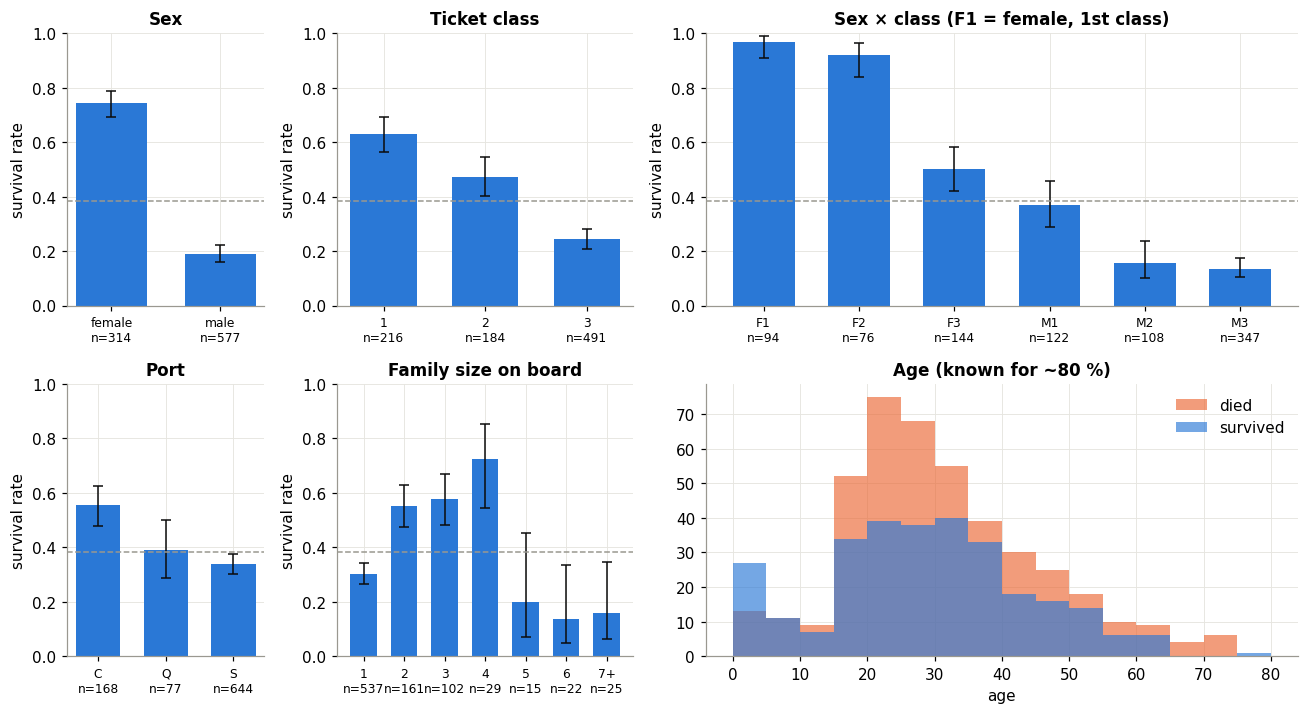

In [3]:
def rate_ci(s, z=1.96):
    """Survival rate and its 95 % Wilson interval."""
    n = len(s); p = s.mean()
    den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return p, c - h, c + h, n


def bar_rates(ax, df, col, order=None, title=None):
    groups = order if order is not None else sorted(df[col].dropna().unique())
    st = [rate_ci(df.loc[df[col] == g, "Survived"]) for g in groups]
    p = np.array([s[0] for s in st])
    ax.bar(range(len(groups)), p, width=0.65, color=BLUE,
           yerr=[p - [s[1] for s in st], [s[2] for s in st] - p], ecolor=INK, capsize=3, error_kw=dict(lw=1))
    ax.axhline(base_rate, color=MUTED, ls="--", lw=1)
    ax.set_xticks(range(len(groups)), [f"{g}\nn={s[3]}" for g, s in zip(groups, st)], fontsize=8)
    ax.set_ylim(0, 1); ax.set_title(title or col); ax.set_ylabel("survival rate")


def rate_table(df, by):
    return df.groupby(by).Survived.agg(n="size", survival="mean").round(2).T


full["SexClass"] = full.Sex.str[0].str.upper() + full.Pclass.astype(str)
full["FamilySize"] = full.SibSp + full.Parch + 1
trf = full[full.is_train == 1]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.6), gridspec_kw={"width_ratios": [2, 3, 6]})
bar_rates(axes[0, 0], trf, "Sex")
bar_rates(axes[0, 1], trf, "Pclass", title="Ticket class")
bar_rates(axes[0, 2], trf, "SexClass", order=["F1", "F2", "F3", "M1", "M2", "M3"], title="Sex × class (F1 = female, 1st class)")
bar_rates(axes[1, 0], trf, "Embarked", order=["C", "Q", "S"], title="Port")
bar_rates(axes[1, 1], trf.assign(Fam=trf.FamilySize.clip(upper=7).astype(str).replace("7", "7+")), "Fam",
          order=["1", "2", "3", "4", "5", "6", "7+"], title="Family size on board")
bins = np.arange(0, 81, 5)
axes[1, 2].hist(trf.loc[trf.Survived == 0, "Age"].dropna(), bins=bins, color=ORANGE, alpha=0.65, label="died")
axes[1, 2].hist(trf.loc[trf.Survived == 1, "Age"].dropna(), bins=bins, color=BLUE, alpha=0.65, label="survived")
axes[1, 2].set_xlabel("age"); axes[1, 2].legend(frameon=False); axes[1, 2].set_title("Age (known for ~80 %)")
plt.tight_layout(); plt.show()

### 2.3 A column hiding inside `Name`
Every name carries a title ("Braund, **Mr.** Owen Harris"). We extract it and merge rare variants, because it may say something about age and status that other columns don't.

Title   Master  Miss   Mr  Mrs  Rare
Sex                                 
female       0   185    0  126     3
male        40     0  517    0    20


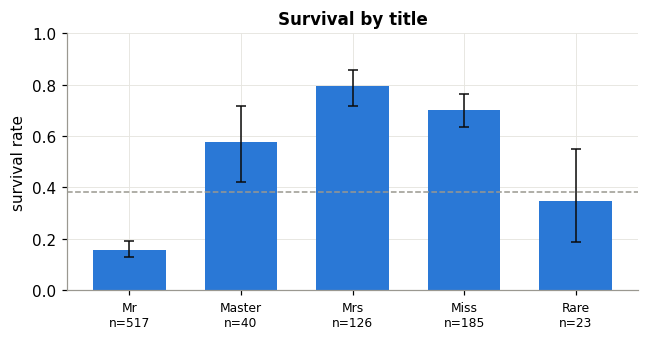

median age by title: {'Master': 3.5, 'Miss': 21.0, 'Mr': 30.0, 'Mrs': 35.0, 'Rare': 48.5}


In [4]:
full["Title"] = full.Name.str.extract(r",\s*([^\.]+)\.")[0].str.strip()
full["Title"] = full.Title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
full.loc[~full.Title.isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"
trf = full[full.is_train == 1]
print(pd.crosstab(trf.Title, trf.Sex).T.to_string())
fig, ax = plt.subplots(figsize=(6, 3.2))
bar_rates(ax, trf, "Title", order=["Mr", "Master", "Mrs", "Miss", "Rare"], title="Survival by title")
plt.tight_layout(); plt.show()
print("median age by title:", trf.groupby("Title").Age.median().round(1).to_dict())

"Master" is used only for males with a median age of a few years, so it marks **boys**.

### 2.4 The simplest rule and its mistakes
The plots above show one dominant column. The simplest rule built on it, "women live, men die", is worth scoring now, because its
**mistakes** show where the rest of the signal must be.

In [5]:
gender_pred_train = (train.Sex == "female").astype(int).values
wrong = trf[gender_pred_train != y]
print(f"'everyone died' is right on {1 - base_rate:.3f};  'women live, men die' is right on {(gender_pred_train == y).mean():.3f}")
print(f"its {len(wrong)} mistakes:  women who died {(wrong.Sex == 'female').sum()},  males who survived {(wrong.Sex == 'male').sum()}"
      f"  (of which boys: {(wrong.Title == 'Master').sum()})")
print("\nmistakes by sex × class:"); print(wrong.SexClass.value_counts().sort_index().to_string())

'everyone died' is right on 0.616;  'women live, men die' is right on 0.787
its 190 mistakes:  women who died 81,  males who survived 109  (of which boys: 23)

mistakes by sex × class:
SexClass
F1     3
F2     6
F3    72
M1    45
M2    17
M3    47


### 2.5 Zooming into the two kinds of mistakes
The mistakes are 3rd-class women who died and males (1st and 3rd class) who survived. Look at each group more closely, and at the
columns we haven't explained yet (cabin, port).

In [6]:
w3 = trf[(trf.Sex == "female") & (trf.Pclass == 3)].copy()
w3["FamilyCat"] = pd.cut(w3.FamilySize, [0, 1, 4, 20], labels=["alone", "small (2-4)", "large (5+)"]).astype(str)
print("3rd-class women by family size:"); print(rate_table(w3, "FamilyCat").to_string())
men = trf[trf.Title == "Mr"]
print("\nadult men (title Mr) by class:"); print(rate_table(men, "Pclass").to_string())
m1 = men[men.Pclass == 1]
print("\n1st-class men by age band:"); print(rate_table(m1.assign(age=pd.cut(m1.Age, [0, 30, 45, 60, 90])), "age").to_string())
print("\nsurvival with cabin known vs unknown, within each class:")
print(rate_table(trf.assign(cabin_known=trf.Cabin.notna()), ["Pclass", "cabin_known"]).to_string())
print("\nclass mix of each port (row shares):"); print(pd.crosstab(trf.Embarked, trf.Pclass, normalize="index").round(2).to_string())
print("\nsurvival by class × port:"); print(rate_table(trf, ["Pclass", "Embarked"]).to_string())

3rd-class women by family size:
FamilyCat  alone  large (5+)  small (2-4)
n          60.00       27.00        57.00
survival    0.62        0.11         0.56

adult men (title Mr) by class:
Pclass         1      2       3
n         107.00  91.00  319.00
survival    0.35   0.09    0.11

1st-class men by age band:
age       (0, 30]  (30, 45]  (45, 60]  (60, 90]
n           23.00     28.00     25.00     11.00
survival     0.43      0.54      0.24      0.09

survival with cabin known vs unknown, within each class:
Pclass           1               2              3      
cabin_known  False   True    False  True    False True 
n            40.00  176.00  168.00  16.00  479.00  12.0
survival      0.48    0.66    0.44   0.81    0.24   0.5

class mix of each port (row shares):
Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55

survival by class × port:
Pclass        1                   2                    3    

/tmp/ipykernel_16/68288647.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(by).Survived.agg(n="size", survival="mean").round(2).T


### 2.6 Who travelled together?
Large families appeared twice above. Do relatives show up in the data? Many passengers share a ticket number, and relatives share a surname.

In [7]:
full["Surname"] = full.Name.str.split(",").str[0]
shared = full.Ticket.map(full.Ticket.value_counts()) > 1
print(f"{shared.sum()} of {len(full)} passengers (train + test) share their ticket with someone")
trf = full[full.is_train == 1]
wc = trf[(trf.Sex == "female") | (trf.Title == "Master")]                 # women and boys
fam = wc.groupby(["Surname", "Ticket"]).Survived.agg(["size", "mean"])
fam = fam[fam["size"] >= 3]
print(f"\nwomen-and-boys groups (same surname + ticket, 3 or more labelled members): {len(fam)}")
print(fam.assign(outcome=fam["mean"].map(lambda m: "all died" if m == 0 else "all survived" if m == 1 else "mixed"))
         .outcome.value_counts().to_string())
for (s, t) in list(fam[fam["mean"] == 0].sort_values("size").index[-2:]):
    print("\n" + wc[(wc.Surname == s) & (wc.Ticket == t)][["Name", "Pclass", "Survived"]].to_string(index=False))

596 of 1309 passengers (train + test) share their ticket with someone

women-and-boys groups (same surname + ticket, 3 or more labelled members): 15
outcome
all died        9
all survived    4
mixed           2

                                           Name  Pclass  Survived
                          Skoog, Master. Harald       3         0
Skoog, Mrs. William (Anna Bernhardina Karlsson)       3         0
                             Skoog, Miss. Mabel       3         0
                  Skoog, Miss. Margit Elizabeth       3         0
                   Skoog, Master. Karl Thorsten       3         0

                                                     Name  Pclass  Survived
                        Andersson, Miss. Ellis Anna Maria       3         0
                     Andersson, Miss. Ingeborg Constanzia       3         0
                        Andersson, Miss. Sigrid Elisabeth       3         0
Andersson, Mrs. Anders Johan (Alfrida Konstantia Brogren)       3         0
           

### 2.7 What we observed
Descriptions only, with no explanations yet:

| # | Observation |
|---|---|
| **O1** | Women survived far more often than men (about 74 % vs 19 %). |
| **O2** | Class modifies it: women in 1st and 2nd class above 90 %, in 3rd class about 50 %; men about 37 % in 1st, about 15 % in 2nd and 3rd. |
| **O3** | "Women live, men die" is right on 78.7 %. Its mistakes are 81 women who died (72 in 3rd class) and 109 males who survived. |
| **O4** | The title "Master" marks boys (median age about 4). Boys survived 57 %, men 16 %. 23 of the 109 surviving males are boys. |
| **O5** | Survival is U-shaped in family size. 3rd-class women in families of 5+ survived only about 11 %. |
| **O6** | 596 of 1,309 passengers share a ticket. Most groups of 3+ women and boys with the same surname and ticket are **unanimous** (all died or all survived). |
| **O7** | Adult men in 1st class: about 35 %. By age, only the 30–45 band is above 50 % (54 % of 28 men). |
| **O8** | Passengers with a recorded cabin survived more often, even within the same class. |
| **O9** | Cherbourg passengers survived more than Southampton ones (55 % vs 34 %), and half of them were 1st class. Within 1st and 2nd class the gap is smaller; within 3rd class Southampton is still much lower (19 % vs 38 %). |

Not every observation needs its own hypothesis. **O9** is partly a *class-mix* effect, a classic confounder: Cherbourg had more 1st-class
passengers. The 3rd-class Southampton gap overlaps with O5, because the large 3rd-class families boarded mostly at Southampton. We park O9 rather than
chase it, and `Embarked` stays in only as a weak model feature.

## 3. From observations to hypotheses
Now we ask **why**, and what each "why" predicts. Every hypothesis cites its source: observations, or **domain knowledge**, which is
legitimate but is a prior the data must confirm. Each one also states up front what would prove it wrong.

| # | Hypothesis | Source | Would be wrong if | Tested in |
|---|---|---|---|---|
| H1 | Sex is the main driver, so the gender rule is a strong baseline | O1–O3 + "women first" | it is not clearly better than "everyone died" | §4 |
| H2 | Boys were protected, so predicting "boys live" improves the gender rule | O4 + "children first" | gain < 2 paired SE | §6 |
| H3 | Large 3rd-class families doomed their women, so "those women die" improves the gender rule | O5 | gain < 2 paired SE | §6 |
| H4 | Women and boys in a family shared one fate, so their relatives' fate predicts them | O5, O6 + "families stay together" | gain of a family rule < 2 paired SE | §7 |
| H5 | Some adult men (1st class, 30–45) are predictable survivors | O7 | gain < 2 paired SE | §6 |
| H6 | A recorded cabin carries information beyond class | O8 | adding it to a model gains < 2 paired SE | §8 |
| H7 | Men in starboard (odd-numbered) cabins survived more | a historical account only | survival is similar on both sides | §6 |
| H8 | Test is drawn like train, so random K-fold CV previews the leaderboard | a validation assumption | adversarial AUC clearly above 0.5 | §5 |
| H9 | A flexible model beats logistic regression on the same features | common practice | within 2 paired SE | §8 |
| H10 | The large-family rule (H3) adds to the family rule (H4) | H3 + H4 | gain < 2 paired SE | §9 |
| H11 | Counting ticket-mates as relatives improves the family rule | O6 | gain < 2 paired SE | §9 |

| H12 | A looser family key (surname only, surname + class, ticket only) links more relatives and improves the family rule | O6 + Deotte's surname-only notebook | gain < 2 paired SE vs the family rule | §9.2 |
| H13 | Letting gradient boosting decide adult men, with the family rule for women and boys, improves on it | H9 + O7 | gain < 2 paired SE | §9.2 |
| H14 | Gradient boosting with family-rule overrides beats gender + family rule | H9 + H4 | gain < 2 paired SE | §9.2 |
| H15 | Deotte's exact published rule (scored 0.823 on the LB in 2018) beats ours | credit check | gain < 2 paired SE | §9.2 |

H12–H15 are raised by the results of §7–§9. One more (H16) is added after the leaderboard result in §12.

## 4. The measuring stick, and H1
Every confirmation below compares predictions, so we fix the measuring stick before seeing any comparison.

**Noise of one score.** For accuracy *p* on *n* rows, the standard error is $\mathrm{SE}=\sqrt{p(1-p)/n}$.

In [8]:
for n, where in [(209, "public LB, if half is scored"), (418, "public LB, if all is scored"), (891, "one CV pass over train")]:
    se = np.sqrt(0.8 * 0.2 / n)
    print(f"{where:24s} n={n}:  SE at p=0.80 = {se:.4f}  →  95 % band ±{1.96 * se:.3f}")

public LB, if half is scored n=209:  SE at p=0.80 = 0.0277  →  95 % band ±0.054
public LB, if all is scored n=418:  SE at p=0.80 = 0.0196  →  95 % band ±0.038
one CV pass over train   n=891:  SE at p=0.80 = 0.0134  →  95 % band ±0.026


How many test passengers does the public LB score? It is either all 418 or about half (209). Chris Deotte's 2018 analysis reports 209,
and our own scores cannot tell the two apart, because both are exact fractions of 209. Either way the LB is noisy: a model whose true accuracy is 0.80
can score anywhere from about 0.76 to 0.84 (418 rows), or 0.75 to 0.85 (209 rows), by luck alone. Two tools sharpen our own measurements:

- **Repeated cross-validation.** One 5-fold CV run depends on how the rows were shuffled, so we repeat it 20 times. Each repeat predicts
  every passenger once *out-of-fold* (by a rule or model built without that passenger), and we average over repeats.
- **Paired comparison.** Two methods scored on the *same* passengers mostly agree, and their shared errors cancel in the difference. For each
  passenger, take $d_i = \text{correct}_A(i) - \text{correct}_B(i)$. The SE of the mean difference, $\mathrm{sd}(d)/\sqrt n$, is much smaller than either score's SE.

**Decision rule (fixed now):** a hypothesis of the form "X improves predictions" is **confirmed** only if X beats the simpler alternative
by **more than 2 paired SE**. A method is a function `fit_predict(train_idx, val_idx)` that may use only the labels of `train_idx`.

In [9]:
tr = full[full.is_train == 1].reset_index(drop=True)
te = full[full.is_train == 0].reset_index(drop=True)
splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(tr, y))


def run_cv(fit_predict):
    """Out-of-fold 0/1 predictions, shape (repeats, 891)."""
    P = np.zeros((N_REPEATS, len(tr)), dtype=int)
    for j, (a, b) in enumerate(splits):
        P[j // N_SPLITS, b] = fit_predict(a, b)
    return P


def paired(a, b):
    """Mean accuracy difference A − B over repeats, and its paired standard error."""
    d = (OOF[a] == y).astype(int) - (OOF[b] == y).astype(int)
    return d.mean(), np.mean([d[r].std(ddof=1) / np.sqrt(len(y)) for r in range(N_REPEATS)])


def report(name, ref):
    m, se = paired(name, ref)
    print(f"{name:40s} CV {np.mean(OOF[name] == y):.4f}   vs {ref}: {m:+.4f}  (paired SE {se:.4f}, {m / se:+.1f} SE)")


gender_fp = lambda a, b: (tr.Sex.values[b] == "female").astype(int)
OOF = {"everyone died": run_cv(lambda a, b: np.zeros(len(b), dtype=int)),
       "gender model (women live)": run_cv(gender_fp)}
report("gender model (women live)", "everyone died")

gender model (women live)                CV 0.7868   vs everyone died: +0.1706  (paired SE 0.0191, +9.0 SE)


**H1: confirmed.** The gender rule beats "everyone died" by many paired SE. It is the **baseline** that every later idea must beat.

## 5. Can CV be trusted? (H8)
Every confirmation that follows relies on CV previewing the test set. So we check that assumption first.
**Adversarial validation:** train a classifier to tell train rows from test rows. If it cannot, the two sets are exchangeable.

In [10]:
adv_X = pd.get_dummies(full[["Pclass", "Sex", "Age", "Fare", "FamilySize", "Embarked", "Title"]], dtype=float)
adv_p = cross_val_predict(HistGradientBoostingClassifier(max_depth=3, random_state=0), adv_X, full.is_train,
                          cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
print(f"adversarial-validation AUC = {roc_auc_score(full.is_train, adv_p):.3f}   (0.5 = indistinguishable)")

adversarial-validation AUC = 0.540   (0.5 = indistinguishable)


**H8: confirmed.** With only 1,309 rows, an AUC a few hundredths above 0.5 is within chance. Stratified K-fold is a fair preview of the test set.

## 6. Single findings as rules (H2, H3, H5, H7)
The most direct test of "X explains some of the baseline's mistakes" is to **change only those predictions** and see whether
out-of-fold accuracy rises by more than 2 paired SE. Each rule starts from the gender baseline. For each one we also count how many of the 418 test
predictions it would change, because a rule that changes many predictions with no real gain only adds leaderboard noise.

In [11]:
def gender_plus(mask_fn, value):
    """Gender baseline, with the rows selected by mask_fn set to `value`."""
    def apply(rows):
        p = (rows.Sex == "female").astype(int).values.copy()
        p[mask_fn(rows).values] = value
        return p
    return (lambda a, b: apply(tr.iloc[b])), apply


RULES = {
    "H2 gender + boys live": (lambda r: r.Title == "Master", 1),
    "H3 gender + large-family 3rd-class women die": (lambda r: (r.Sex == "female") & (r.Pclass == 3) & (r.FamilySize >= 5), 0),
    "H5 gender + 1st-class men 30-45 live": (lambda r: (r.Title == "Mr") & (r.Pclass == 1) & r.Age.between(30, 45), 1),
}
gender_test = (te.Sex == "female").astype(int).values
for name, (mask, value) in RULES.items():
    fp, apply = gender_plus(mask, value)
    OOF[name] = run_cv(fp)
    report(name, "gender model (women live)")
    print(f"{'':40s} changes {(apply(te) != gender_test).sum()} of 418 test predictions")

H2 gender + boys live                    CV 0.7935   vs gender model (women live): +0.0067  (paired SE 0.0071, +0.9 SE)
                                         changes 21 of 418 test predictions
H3 gender + large-family 3rd-class women die CV 0.8103   vs gender model (women live): +0.0236  (paired SE 0.0058, +4.1 SE)
                                         changes 5 of 418 test predictions
H5 gender + 1st-class men 30-45 live     CV 0.7879   vs gender model (women live): +0.0011  (paired SE 0.0060, +0.2 SE)
                                         changes 19 of 418 test predictions


**H3: confirmed.** Predicting "died" for 3rd-class women in large families clears the bar comfortably.

**H2: not confirmed, although O4 is real.** Boys survived far more than men, but at about 57 % they are only *barely* a majority. A blanket
"boys live" rule is right on about 57 % of the boys it touches and wrong on about 43 %, so the net gain is small and within noise.
**For accuracy, a feature helps only where it moves a group clearly across 50 %.** Hold on to this: §7 shows how to use boys *selectively*.

**H5: rejected, and a warning.** 1st-class men aged 30–45 sit at about 54 %, a coin flip. The rule's mean gain is noise, yet it changes a
number of test predictions. Such a rule adds **leaderboard variance with no expected gain**: it might score ±1 % by luck, and keeping it because the
public LB went up would be overfitting 418 rows (the winner's curse). The same reasoning explains why most surviving men (O3) cannot be recovered.

**H7, a story worth testing.** A historical account says one officer let men into boats on the starboard side (odd cabin numbers), while
the other loaded only women and children on the port side.

In [12]:
cab = tr[tr.Cabin.notna()].assign(num=lambda d: d.Cabin.str.extract(r"(\d+)")[0].astype(float)).dropna(subset=["num"])
cab["side"] = np.where(cab.num % 2 == 1, "odd (starboard)", "even (port)")
print(rate_table(cab, ["Sex", "side"]).to_string())

Sex           female                        male                
side     even (port) odd (starboard) even (port) odd (starboard)
n               42.0           53.00       66.00           39.00
survival         0.9            0.96        0.42            0.44


**H7: rejected.** Men's survival is the same on both sides. Whatever happened at the boats, cabin side does not carry it in this data.
Note that this is a test on the data, not a story we encoded first. **Test stories; don't encode them.**

## 7. Families (H4)
### 7.1 Defining a family (record linkage)
O6 used surname + ticket. For the rule we need a sturdier key:
- **Surname alone collides.** There are several unrelated families called Andersson.
- So we combine **surname + class + ticket (without its last digit) + port + fare**. Dropping the last ticket digit merges consecutively numbered tickets bought together.
- The key is computed on **train and test together**. That uses no labels, and it links each test passenger to their relatives in train.
- We use **women and boys only**. Adult men mostly died even when their family survived (O1, O7), so their fate says little about the rest.

In [13]:
full["Boy"] = full.Title == "Master"
full["WC"] = (full.Sex == "female") | full.Boy
full["Group"] = (full.Surname + "|" + full.Pclass.astype(str) + "|" + full.Ticket.str[:-1] + "|"
                 + full.Embarked.fillna("S") + "|" + full.Fare.round(2).astype(str))
tr = full[full.is_train == 1].reset_index(drop=True)          # same row order, now with the family key
te = full[full.is_train == 0].reset_index(drop=True)

### 7.2 Is the unanimity in O6 more than chance? (exploratory)
If outcomes were independent with survival rate *p*, a family of *k* would be unanimous with probability pᵏ + (1−p)ᵏ.
*Caution:* this uses the same training data that produced O6, so it can only show that the pattern is not a fluke of small families.
It cannot confirm that the pattern *predicts*. That is §7.3's job.

In [14]:
fam = tr[tr.WC].groupby("Group").Survived.agg(["size", "mean"])
g = fam[fam["size"] >= 2]
p_wc = tr[tr.WC].Survived.mean()
observed = ((g["mean"] == 0) | (g["mean"] == 1)).mean()
expected = (p_wc ** g["size"] + (1 - p_wc) ** g["size"]).mean()
print(f"{len(g)} families with ≥2 labelled women/boys (their survival p = {p_wc:.2f})")
print(f"unanimous families: observed {observed:.2f}   expected if independent {expected:.2f}")

48 families with ≥2 labelled women/boys (their survival p = 0.72)
unanimous families: observed 0.96   expected if independent 0.50


Far more unanimous than chance. The suggestion is strong, so now the confirmation.

### 7.3 The woman-child-group (WCG) rule (confirmatory)
The smallest rule that uses H4 targets exactly the baseline's two kinds of mistakes (O3):
- a **boy** whose labelled women/boys relatives **all survived** → predict *survived*. This is the *selective* use of boys that H2 lacked.
- a **woman** whose labelled women/boys relatives **all died** → predict *died*. This generalises H3 from "large family" to "this family".

**Credit:** this rule comes from Chris Deotte's notebooks [Titanic using Name only [0.81818]](https://www.kaggle.com/code/cdeotte/titanic-using-name-only-0-81818)
and [Titanic WCG+XGBoost [0.84688]](https://www.kaggle.com/code/cdeotte/titanic-wcg-xgboost-0-84688). Read them. The second also models
which adult males survive. Here it is derived from O4–O6 and confirmed out-of-fold.

**The leak to avoid.** "Labelled relatives" must mean relatives **in the training fold only**. Using a validation passenger's own label, or a
validation relative's label, would inflate the score. This is *out-of-fold target encoding*: a group statistic (the family's women-and-boys
survival) computed only from rows the method may see. For the test set all 891 training labels may be used, which is exactly what the folds simulate.

In [15]:
def wcg_adjust(pred, rows, lab_rows, lab_y):
    """Override base predictions for boys/women using the fate of their *labelled* women/boys relatives."""
    lab = lab_rows.assign(y=lab_y)[lab_rows.WC.values]
    grp_mean = rows.Group.map(lab.groupby("Group").y.mean())      # NaN when no labelled relative
    pred = np.asarray(pred).copy()
    pred[(rows.Boy & (grp_mean == 1)).values] = 1
    pred[((rows.Sex == "female") & (grp_mean == 0)).values] = 0
    return pred


def with_wcg(base_fp):
    return lambda a, b: wcg_adjust(base_fp(a, b), tr.iloc[b], tr.iloc[a], y[a])


OOF["gender + WCG rule"] = run_cv(with_wcg(gender_fp))
report("gender + WCG rule", "gender model (women live)")
for h in ["H2 gender + boys live", "H3 gender + large-family 3rd-class women die"]:
    report("gender + WCG rule", h)
wcg_test = wcg_adjust(gender_test, te, tr, y)
print(f"\non the test set the WCG rule changes {(wcg_test != gender_test).sum()} of 418 gender-model predictions")

gender + WCG rule                        CV 0.8402   vs gender model (women live): +0.0534  (paired SE 0.0077, +6.9 SE)
gender + WCG rule                        CV 0.8402   vs H2 gender + boys live: +0.0467  (paired SE 0.0085, +5.5 SE)
gender + WCG rule                        CV 0.8402   vs H3 gender + large-family 3rd-class women die: +0.0299  (paired SE 0.0060, +5.0 SE)

on the test set the WCG rule changes 16 of 418 gender-model predictions


**H4: confirmed**, and it is the largest gain in this notebook relative to its paired SE. It also beats the H3 rule it generalises,
and it succeeds with boys where H2's blanket rule failed. The difference is **selectivity**: the rule only changes a prediction when the
family's fate gives direct evidence, so most of its changes are right.

## 8. Features and models (H9, H6)
The other route is to put the confirmed findings into features and let a model learn the weights:

| Feature | From |
|---|---|
| `Sex`, `Pclass` | O1, O2 (H1) |
| `Title` | O4. Even though the blanket rule (H2) failed, a model can combine title with other columns. |
| `FamilyCat`: alone / small (2–4) / large (5+) | O5 (H3): the U-shape, which a linear model cannot learn from the raw count |
| `CabinKnown` | O8 (H6, tested below) |
| `Age` (median-imputed + "was missing" flag), `log(fare per person)`, `Embarked` | the remaining columns. Fare is per *ticket*, so we divide it by the people on the ticket. |

Anything learned from data (imputation values, scaling, one-hot categories) goes inside a scikit-learn **`Pipeline`**, so it is fit on
the training fold only. Fitting an imputer on all rows before CV would leak a little information from the validation fold.

In [16]:
full["FamilyCat"] = pd.cut(full.FamilySize, [0, 1, 4, 20], labels=["alone", "small", "large"]).astype(str)
full["TicketCount"] = full.groupby("Ticket").Ticket.transform("count")
full["LogFarePP"] = np.log1p(full.Fare / full.TicketCount)
full["CabinKnown"] = full.Cabin.notna().astype(int)
tr = full[full.is_train == 1].reset_index(drop=True)
te = full[full.is_train == 0].reset_index(drop=True)

NUM = ["Age", "LogFarePP", "Pclass", "CabinKnown"]
CAT = ["Sex", "Title", "FamilyCat", "Embarked"]


def make_model(kind, num=NUM):
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), CAT),
    ])
    est = {"logistic regression": LogisticRegression(C=0.3, max_iter=1000),
           "random forest": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
           "gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                                               l2_regularization=1.0, random_state=SEED)}[kind]
    return make_pipeline(pre, est)


def model_fp(kind, num=NUM):
    return lambda a, b: make_model(kind, num).fit(tr.iloc[a][num + CAT], y[a]).predict(tr.iloc[b][num + CAT])


for kind in ["logistic regression", "random forest", "gradient boosting"]:
    t = time.time(); OOF[kind] = run_cv(model_fp(kind)); report(kind, "gender model (women live)")
print()
report("gradient boosting", "logistic regression")
report("random forest", "logistic regression")

logistic regression                      CV 0.8256   vs gender model (women live): +0.0388  (paired SE 0.0099, +3.9 SE)
random forest                            CV 0.8273   vs gender model (women live): +0.0405  (paired SE 0.0096, +4.2 SE)
gradient boosting                        CV 0.8362   vs gender model (women live): +0.0494  (paired SE 0.0115, +4.3 SE)

gradient boosting                        CV 0.8362   vs logistic regression: +0.0106  (paired SE 0.0087, +1.2 SE)
random forest                            CV 0.8273   vs logistic regression: +0.0017  (paired SE 0.0073, +0.2 SE)


Every model beats the gender baseline clearly, so the features carry real signal.

**H9: rejected.** Gradient boosting comes out a little ahead of logistic regression, but by less than the 2-SE bar. On 891 rows we cannot reliably
tell the models apart: **the features matter, the model family barely does.**

Now H6. O8 showed that a recorded cabin goes with survival even within a class. Does that help a model that already knows class and fare?

In [17]:
NUM_NO_CABIN = ["Age", "LogFarePP", "Pclass"]
OOF["logistic regression without CabinKnown"] = run_cv(model_fp("logistic regression", NUM_NO_CABIN))
report("logistic regression", "logistic regression without CabinKnown")

logistic regression                      CV 0.8256   vs logistic regression without CabinKnown: +0.0016  (paired SE 0.0040, +0.4 SE)


**H6: not confirmed, although O8 is real.** The cabin pattern exists, but once class, fare and title are in the model, `CabinKnown` adds no
detectable accuracy. This is the second case where EDA shows something real that does not survive confirmation. The *reason* for O8 is still
worth knowing: cabin records were partly reconstructed afterwards from survivors' accounts, so whether the value is missing depends on the outcome
("missing not at random"). In a real deployment such a field would be a **leak**, because you would not have records that exist *because of* the
outcome. Always ask when and why a value was recorded.

The logistic regression's coefficients show what the features learned:

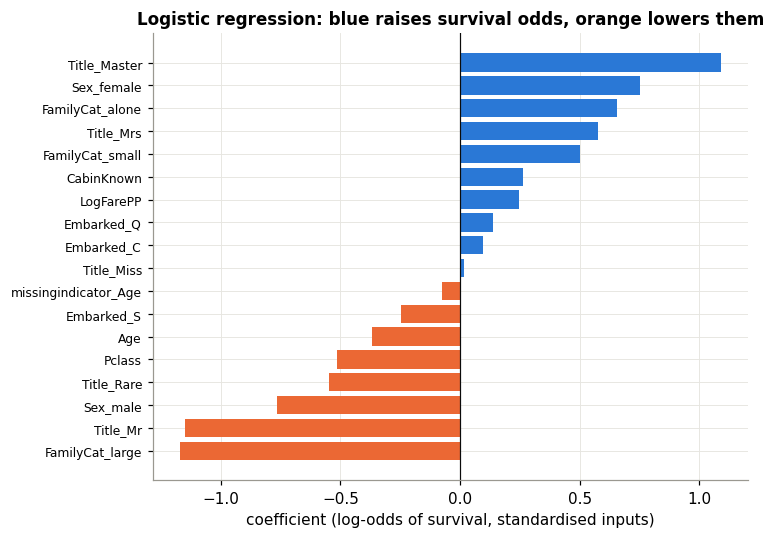

In [18]:
lr = make_model("logistic regression").fit(tr[NUM + CAT], y)
names = lr[0].get_feature_names_out(); coef = lr[-1].coef_[0]
order = np.argsort(coef)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(range(len(coef)), coef[order], color=[BLUE if c > 0 else ORANGE for c in coef[order]])
ax.set_yticks(range(len(coef)), [n.split("__")[1] for n in names[order]], fontsize=8)
ax.axvline(0, color=INK, lw=0.8); ax.set_xlabel("coefficient (log-odds of survival, standardised inputs)")
ax.set_title("Logistic regression: blue raises survival odds, orange lowers them"); plt.tight_layout(); plt.show()

Sex, title, class and a large family dominate, consistent with O1–O5. What the features *cannot* express is H4: how a passenger's
own relatives fared. So, does a model add anything on top of the family rule? And how does the rule compare with the best model?

In [19]:
OOF["logistic regression + WCG"] = run_cv(with_wcg(model_fp("logistic regression")))
report("logistic regression + WCG", "gender + WCG rule")
report("gender + WCG rule", "gradient boosting")

logistic regression + WCG                CV 0.8393   vs gender + WCG rule: -0.0008  (paired SE 0.0074, -0.1 SE)
gender + WCG rule                        CV 0.8402   vs gradient boosting: +0.0040  (paired SE 0.0098, +0.4 SE)


The family rule is level with the best model (within noise), and a model on top of it adds nothing. Once a family's fate is known, the other
columns carry no further detectable information. The rule is three lines that you can explain.

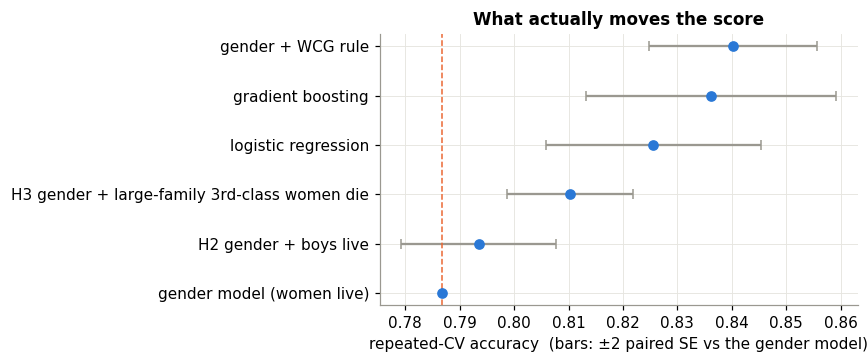

In [20]:
show = ["everyone died", "gender model (women live)", "H2 gender + boys live", "H3 gender + large-family 3rd-class women die",
        "logistic regression", "gradient boosting", "gender + WCG rule"]
ref = "gender model (women live)"
acc_ = [np.mean(OOF[s] == y) for s in show[1:]]
se_ = [paired(s, ref)[1] for s in show[1:]]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(acc_, range(len(acc_)), xerr=[2 * s for s in se_], fmt="o", color=BLUE, ecolor=MUTED, capsize=3)
ax.axvline(np.mean(OOF[ref] == y), color=ORANGE, ls="--", lw=1)
ax.set_yticks(range(len(acc_)), show[1:]); ax.set_xlabel("repeated-CV accuracy  (bars: ±2 paired SE vs the gender model)")
ax.set_title("What actually moves the score"); plt.tight_layout(); plt.show()

## 9. Combining and extending the family rule (H10, H11)
Two last ideas, each judged against **gender + WCG**:
- **H10:** H3 was confirmed on its own. Does it still add anything once the family rule is in place?
- **H11 (from O6):** also count women and boys who share a *ticket* as relatives, to catch friends, nannies, and cousins with other surnames.

In [21]:
def wcg_ticket_adjust(pred, rows, lab_rows, lab_y):
    """WCG where relatives = same family Group OR same Ticket."""
    lab = lab_rows.assign(y=lab_y)[lab_rows.WC.values]
    pred = np.asarray(pred).copy()
    for k, (i, r) in enumerate(rows.iterrows()):
        rel = lab[((lab.Group == r.Group) | (lab.Ticket == r.Ticket)) & (lab.index != i)]
        if len(rel) == 0: continue
        if r.Boy and rel.y.mean() == 1: pred[k] = 1
        if r.Sex == "female" and rel.y.mean() == 0: pred[k] = 0
    return pred


large_mask = lambda r: (r.Sex == "female") & (r.Pclass == 3) & (r.FamilySize >= 5)
h3_fp, h3_apply = gender_plus(large_mask, 0)
OOF["H10 WCG + large-family rule"] = run_cv(lambda a, b: wcg_adjust(h3_fp(a, b), tr.iloc[b], tr.iloc[a], y[a]))
OOF["H11 WCG + ticket links"] = run_cv(lambda a, b: wcg_ticket_adjust((tr.Sex.values[b] == "female").astype(int), tr.iloc[b], tr.iloc[a], y[a]))
report("H10 WCG + large-family rule", "gender + WCG rule")
report("H11 WCG + ticket links", "gender + WCG rule")

H10 WCG + large-family rule              CV 0.8371   vs gender + WCG rule: -0.0030  (paired SE 0.0020, -1.5 SE)
H11 WCG + ticket links                   CV 0.8395   vs gender + WCG rule: -0.0007  (paired SE 0.0007, -1.0 SE)


**H10: rejected (slightly negative).** Once the family rule knows a family's fate, the large-family rule only adds its cases *without* a
labelled relative, and those are wrong often enough to cancel out. A finding confirmed alone can be **redundant** with a better one.

**H11: rejected.** Nearly everyone who can be linked is already linked by the family key.

### 9.2 Can anything beat the family rule? (H12–H15)
The family rule (H4) is the best method so far. The obvious next ideas each get the same test against it:
- **H12:** a **looser family key** (surname only, surname + class, or ticket only) links more passengers to labelled relatives. Chris Deotte's well-known
  version groups by surname only, and it scored 0.818–0.823 on the 2018 leaderboard.
- **H13:** gradient boosting found extra signal (§8). Perhaps it can pick out **which adult men** survived, while the family rule handles women and boys.
- **H14:** use **gradient boosting with family-rule overrides** instead of the gender baseline with overrides.
- **H15 (credit check):** port **Deotte's exact rule** from his R code (surname groups excluding men, size ≥ 2, a ticket fix for singletons) and compare.
  The port is checked against his notebook: it must change the same number of test predictions he reports (18).

In [22]:
def wcg_by(key):
    """The family rule with a different family key column."""
    def adjust(pred, rows, lab_rows, lab_y):
        lab = lab_rows.assign(y=lab_y)[lab_rows.WC.values]
        gm = rows[key].map(lab.groupby(key).y.mean())
        pred = np.array(pred).copy()
        pred[(rows.Boy & (gm == 1)).values] = 1
        pred[((rows.Sex == "female") & (gm == 0)).values] = 0
        return pred
    return adjust


# Deotte's groups: title → man / woman / boy; surname for women and boys only; groups of 1 dropped; singletons joined by ticket
MAN = {"Capt", "Don", "Major", "Col", "Rev", "Dr", "Sir", "Mr", "Jonkheer"}
WOMAN = {"Dona", "the Countess", "Mme", "Mlle", "Ms", "Miss", "Lady", "Mrs"}
raw_title = full.Name.str.extract(r",\s*([^\.]+)\.")[0].str.strip()
full["DTitle"] = np.where(raw_title.isin(MAN), "man", np.where(raw_title.isin(WOMAN), "woman",
                          np.where(raw_title == "Master", "boy", "other")))
dg = full.Surname.where(full.DTitle != "man", "noGroup")
dg = dg.where(dg.map(dg.value_counts()) > 1, "noGroup")
for i in full.index[(full.DTitle != "man") & (dg == "noGroup")]:
    dg[i] = dg[full.Ticket == full.Ticket[i]].iloc[0]
full["DeotteGroup"] = dg
full["KeySurname"] = full.Surname
full["KeySurnameClass"] = full.Surname + "|" + full.Pclass.astype(str)
full["KeyTicket"] = full.Ticket
tr = full[full.is_train == 1].reset_index(drop=True)
te = full[full.is_train == 0].reset_index(drop=True)
gender_of = lambda rows: np.array((rows.Sex == "female").astype(int).values)
vs_ours = lambda p: int((np.asarray(p) != wcg_test).sum())

for key, label in [("KeySurname", "surname only"), ("KeySurnameClass", "surname + class"), ("KeyTicket", "ticket only")]:
    adj, name = wcg_by(key), f"H12 family key = {label}"
    OOF[name] = run_cv(lambda a, b, adj=adj: adj(gender_of(tr.iloc[b]), tr.iloc[b], tr.iloc[a], y[a]))
    report(name, "gender + WCG rule")
    print(f"{'':40s} differs from our submission on {vs_ours(adj(gender_test, te, tr, y))} test passengers")


def gb_for_men(lab_rows, lab_y, rows):
    gb = make_model("gradient boosting").fit(lab_rows[NUM + CAT], lab_y).predict(rows[NUM + CAT])
    p = gender_of(rows); men = (rows.Title == "Mr").values; p[men] = gb[men]
    return wcg_adjust(p, rows, lab_rows, lab_y)


OOF["H13 GB decides adult men + WCG"] = run_cv(lambda a, b: gb_for_men(tr.iloc[a], y[a], tr.iloc[b]))
report("H13 GB decides adult men + WCG", "gender + WCG rule")
men_oof = OOF["gradient boosting"][:, (tr.Title == "Mr").values].mean()
print(f"{'':40s} gradient boosting predicts 'survived' for {men_oof:.1%} of adult men out-of-fold;"
      f" differs from our submission on {vs_ours(gb_for_men(tr, y, te))} test passengers")

OOF["H14 GB + WCG"] = run_cv(with_wcg(model_fp("gradient boosting")))
report("H14 GB + WCG", "gender + WCG rule")
gb_test = make_model("gradient boosting").fit(tr[NUM + CAT], y).predict(te[NUM + CAT])
print(f"{'':40s} differs from our submission on {vs_ours(wcg_adjust(gb_test, te, tr, y))} test passengers")


def deotte_rule(rows, lab_rows, lab_y):
    rate = rows.DeotteGroup.map(lab_rows.assign(y=lab_y).groupby("DeotteGroup").y.mean())
    p = np.array((rows.DTitle == "woman").astype(int).values)
    p[((rows.DTitle == "boy") & (rate == 1)).values] = 1
    p[((rows.DTitle == "woman") & (rate == 0)).values] = 0
    return p


OOF["H15 Deotte's exact rule"] = run_cv(lambda a, b: deotte_rule(tr.iloc[b], tr.iloc[a], y[a]))
deotte_test = deotte_rule(te, tr, y)
print(f"port check: Deotte's rule changes {(deotte_test != gender_test).sum()} test predictions vs the gender model (his notebook reports 18)")
report("H15 Deotte's exact rule", "gender + WCG rule")
print(f"{'':40s} differs from our submission on {vs_ours(deotte_test)} test passengers")

H12 family key = surname only            CV 0.8354   vs gender + WCG rule: -0.0048  (paired SE 0.0030, -1.6 SE)
                                         differs from our submission on 1 test passengers
H12 family key = surname + class         CV 0.8363   vs gender + WCG rule: -0.0039  (paired SE 0.0028, -1.4 SE)
                                         differs from our submission on 1 test passengers
H12 family key = ticket only             CV 0.8363   vs gender + WCG rule: -0.0039  (paired SE 0.0020, -2.0 SE)
                                         differs from our submission on 3 test passengers
H13 GB decides adult men + WCG           CV 0.8425   vs gender + WCG rule: +0.0024  (paired SE 0.0056, +0.4 SE)
                                         gradient boosting predicts 'survived' for 4.8% of adult men out-of-fold; differs from our submission on 9 test passengers
H14 GB + WCG                             CV 0.8442   vs gender + WCG rule: +0.0040  (paired SE 0.0092, +0.4 SE)
       

**H12: rejected.** Every looser key is *worse*. Surname-only groups link unrelated namesakes (for example, several unrelated Andersson families), and their fates
contaminate the rule. Record linkage needs enough fields to be specific.

**H13: not confirmed.** Out-of-fold, gradient boosting predicts survival for only a few percent of adult men, the accuracy limit from H2/H5 again,
so it barely changes anything.

**H14: not confirmed, and risky.** Its CV is a little higher, but well within noise, and it changes many test predictions. That is the profile
of a submission that moves the public LB by luck. Keeping it because the LB went up would be the winner's curse.

**H15: rejected, and a lesson about leaderboards.** The port reproduces Deotte's notebook (same 18 changed predictions, and a CV in line with the 83.6 % he reports).
By our CV it is slightly below our rule, and its test predictions differ from ours on only a couple of passengers. So his 0.818–0.823 against our 0.799 **cannot**
come from the rules: two passengers cannot move a score by about 5 points. His score was measured on the 2018 leaderboard (209 scored passengers, possibly a different split).
**Compare predictions and CV, never leaderboard numbers from different times or splits.**

**Conclusion:** about 0.84 out-of-fold is the honest ceiling for this data. The remaining ideas move the LB by luck, not skill.

## 10. What errors remain?
Error rates of the best method by sex × class (out-of-fold, averaged over repeats):

In [23]:
CANDIDATES = ["gender model (women live)", "gender + WCG rule", "logistic regression", "logistic regression + WCG",
              "random forest", "gradient boosting", "H13 GB decides adult men + WCG", "H14 GB + WCG"]   # simplest first
best = max(CANDIDATES, key=lambda s: np.mean(OOF[s] == y))
err = (OOF[best] != y).mean(0)
tab = (tr.assign(err=err).groupby("SexClass")
         .agg(passengers=("err", "size"), error_rate=("err", "mean"), errors=("err", "sum")).round(3))
print(f"best method: {best}")
tab.sort_values("errors", ascending=False)

best method: H14 GB + WCG


,passengers,error_rate,errors
SexClass,,,
M1,122,0.342,41.70
F3,144,0.286,41.25
M3,347,0.110,38.00
M2,108,0.083,9.00
F2,76,0.082,6.25
F1,94,0.028,2.65


**Reading it.** The remaining errors are the two groups from O3, now smaller: **men who survived**, which H5 showed cannot be predicted under
accuracy, and **3rd-class women who died** without labelled relatives to reveal their family's fate. This is the irreducible part for this
data, and it is why honest scores plateau in the low 0.80s.

## 11. Submission
Apply the §4 rule one last time: among methods within 2 paired SE of the best, take the **simplest**. The candidates include H13 and H14, so the
rule, not our preference, decides between them and the family rule. Then refit on all 891 passengers and predict the 418.

In [24]:
choice = best
for cand in CANDIDATES:
    m, se = paired(cand, best)
    if m >= -2 * se:
        choice = cand; break
print(f"best CV: {best}   →   chosen (simplest within 2 paired SE): {choice}")

if choice == "gender model (women live)":
    pred = gender_test
elif choice == "gender + WCG rule":
    pred = wcg_test
elif choice == "H13 GB decides adult men + WCG":
    pred = gb_for_men(tr, y, te)
elif choice == "H14 GB + WCG":
    pred = wcg_adjust(gb_test, te, tr, y)
else:
    kind = choice.replace(" + WCG", "")
    pred = make_model(kind).fit(tr[NUM + CAT], y).predict(te[NUM + CAT])
    if choice.endswith("+ WCG"):
        pred = wcg_adjust(pred, te, tr, y)

sub = pd.DataFrame({"PassengerId": test.PassengerId, "Survived": pred.astype(int)})
sub.to_csv(OUT_DIR / "submission.csv", index=False)
assert sub.shape == (418, 2) and sub.Survived.isin([0, 1]).all()
print(f"wrote {OUT_DIR / 'submission.csv'}   predicted survival rate {sub.Survived.mean():.3f} (train: {base_rate:.3f})")
print(f"expected LB ≈ CV {np.mean(OOF[choice] == y):.3f}, ± ~0.04–0.05 from leaderboard noise (§4)")

best CV: H14 GB + WCG   →   chosen (simplest within 2 paired SE): gender + WCG rule
wrote /kaggle/working/submission.csv   predicted survival rate 0.364 (train: 0.384)
expected LB ≈ CV 0.840, ± ~0.04–0.05 from leaderboard noise (§4)


## 12. What the leaderboard said (H16)
This submission (gender + WCG rule) scored **0.79904** on the public LB, below the CV estimate of 0.840. The leaderboard result raises one last hypothesis:

> **H16: The LB is below CV because our method overfit the training data.**
> *Would be wrong if:* a fixed baseline scored on the *same* 418 passengers drops by about as much, which would mean the test sample is harder,
> not that our method is worse. `gender_submission.csv` (women live, men die) scores **0.76555** on the same leaderboard.
> (Whether that leaderboard scores 418 or 209 passengers is unknown; see §4. We work through both cases.)

In [25]:
LB_GENDER, LB_OURS = 0.76555, 0.79904        # public LB of gender_submission.csv and of this notebook's submission
n_changed = int((wcg_test != gender_test).sum())
print(f"the WCG rule changes {n_changed} of the gender model's 418 test predictions")
for n_scored in (418, 209):
    g, o = LB_GENDER * n_scored, LB_OURS * n_scored
    print(f"if the LB scores {n_scored} passengers: gender {g:.1f} correct, ours {o:.1f} correct  →  the changes are net {o - g:+.0f} correct")
print(f"gender model: CV {np.mean(OOF['gender model (women live)'] == y):.3f} on train vs LB {LB_GENDER:.3f} on test")

the WCG rule changes 16 of the gender model's 418 test predictions
if the LB scores 418 passengers: gender 320.0 correct, ours 334.0 correct  →  the changes are net +14 correct
if the LB scores 209 passengers: gender 160.0 correct, ours 167.0 correct  →  the changes are net +7 correct
gender model: CV 0.787 on train vs LB 0.766 on test


**H16: rejected.** Read the numbers in both possible cases:
- **If the LB scores all 418 passengers,** our 16 changes are net +14, so **15 right and 1 wrong**.
- **If it scores 209,** the changes that fall in the scored half are net +7, so at most a few of them can be wrong.

Either way, the family rule did its job on unseen passengers. The gap between CV (0.840) and LB (0.799) comes from the **baseline**: "women live,
men die" scores 0.787 out-of-fold on train but only 0.766 on the leaderboard passengers, who happen to include more men who survived and women who died.
That is a draw of the test sample, about 1–2 SE in size (§4), and no modelling choice could have changed it.

**How to use this anywhere:** when LB and CV disagree, score a fixed, simple baseline on both. If the baseline moves by the same amount, the test
sample is harder or easier, and your CV-based decisions stand. If only your model moves, look for overfitting or a leak.

## Hypothesis log
| # | Hypothesis | Source | Evidence | Verdict |
|---|---|---|---|---|
| H1 | The gender rule is a strong baseline | O1–O3 + domain | out-of-fold CV | **confirmed** |
| H2 | "Boys live" improves the gender rule | O4 + domain | out-of-fold CV | **not confirmed**: real pattern, but 57 % is too close to 50 % |
| H3 | "Large-family 3rd-class women die" improves the gender rule | O5 | out-of-fold CV | **confirmed** (later made redundant by H4) |
| H4 | Relatives' fate predicts women and boys (WCG) | O5, O6 + domain | exploratory (unanimity) then out-of-fold CV | **confirmed**: the submission |
| H5 | 1st-class men aged 30–45 are predictable | O7 | out-of-fold CV | **rejected**: noise that adds LB variance |
| H6 | A recorded cabin adds information beyond class | O8 | out-of-fold CV (ablation) | **not confirmed**: real pattern, and a production leak |
| H7 | Starboard cabins saved men | historical account | descriptive | **rejected** |
| H8 | Test is drawn like train | validation assumption | adversarial validation | **confirmed** |
| H9 | A flexible model beats logistic regression | common practice | out-of-fold CV | **rejected**: within noise |
| H10 | The large-family rule adds to WCG | H3 + H4 | out-of-fold CV | **rejected**: redundant |
| H11 | Ticket-mates improve WCG | O6 | out-of-fold CV | **rejected** |
| H12 | A looser family key improves WCG | O6 + Deotte | out-of-fold CV | **rejected**: it links unrelated namesakes |
| H13 | Gradient boosting for adult men + WCG | H9 + O7 | out-of-fold CV | **not confirmed**: almost no man is predicted to survive |
| H14 | Gradient boosting + WCG overrides | H9 + H4 | out-of-fold CV | **not confirmed**: within noise, many changed predictions |
| H15 | Deotte's exact rule beats ours | credit check | out-of-fold CV + prediction diff | **rejected**: slightly lower CV; differs from ours on 2 test passengers |
| H16 | LB below CV means overfitting | the LB result | baseline on the same rows | **rejected**: the gender baseline drops by about as much |

## What transfers to medal competitions
| Habit | Where it appeared |
|---|---|
| Describe first (observations), explain second (hypotheses) | §2 → §3 |
| Score the simplest rule early and read its mistakes | §2.4 |
| Name confounders instead of chasing them | O9 |
| Fix a noise budget and a decision rule before comparing anything | §4 |
| Confirm on data that did not suggest the hypothesis (out-of-fold CV) | §6–§9 |
| For thresholded metrics, a feature helps only where it moves a group clearly across the threshold | H2, H5 |
| Selective rules beat blanket rules | H4 vs H2, H3 |
| A real pattern is not automatically a useful feature | H2, H6 |
| Link rows that belong to the same family, user, device or account; compute group statistics out-of-fold | §7 |
| Check that CV mimics test, and ask why values are missing | H8, H6 |
| Keep rejected hypotheses: most ideas fail, and the simpler option wins ties | H5, H9–H14 |
| Compare predictions and CV, never LB numbers from different times or splits | H15 |
| Read the LB against a baseline on the same rows | H16 |